# 01 · Datos de origen y exploración

Relectura de los cinco CSV y exploración del desarrollo. Requiere originales en `.local/datos/` y snapshot en `.local/modelado/`; se pueden indicar mediante PSET4_DATA_DIR y PSET4_MODELADO_DIR. No modifica PSet1.

**Alcance de validación.** 2014J ya se había observado en una versión anterior. **No es una prueba final independiente ni un hold-out de un solo uso.** Separar personas y ajustar transformaciones dentro de cada fold evita fugas directas, pero no elimina el conocimiento previo de sus resultados. Las cifras sobre 2014J describen este histórico; la decisión institucional necesita una cohorte futura sin consultar, con protocolo fijado antes de conocer resultados.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p/'src/notebooks.py').is_file()), None)
if ROOT is None and (here/'proyecto_final/src/notebooks.py').is_file():
    ROOT = here/'proyecto_final'
assert ROOT is not None, 'Abrir desde proyecto_final o notebooks.'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT/'.local/matplotlib')
os.environ['PSET4_MODEL_MODE'] = 'fixture'
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.notebooks import evidencia
from src.datos import sha256
E = evidencia()
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 32)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
%matplotlib inline
print('Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.')


Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.


## Validar PSet1 desde los originales

Se contrastan huellas SHA256, tamaños, claves, faltantes, integridad referencial, clases y poblaciones elegibles con la auditoría original. El conteo de duplicados dentro de bloques no es una comprobación global de unicidad.

In [2]:
from src.notebooks import auditar_pset1
A = auditar_pset1()
assert A['estado'] == 'verificado'
(ROOT/'docs/validacion_pset1.json').write_text(json.dumps(A, ensure_ascii=False, indent=2)+'\n')
display(pd.DataFrame(A['archivos']).T[['bytes','sha256']])
display(pd.DataFrame(A['poblaciones']['cuts']).T)
print('Matrículas originales:', A['poblaciones']['original'])
print('Personas distintas:', A['poblaciones']['unique_students'])
print('Filas de actividad:', A['checks']['studentVle']['rows'], '| clics:', A['clics_totales'])


,bytes,sha256
studentInfo.csv,3461652,7e6f3e474a5eee00639d2a414a6c7e928745823c2d2c25...
studentRegistration.csv,1109984,0d32676285372aaf2e7a80304e5b274b4fba24313e2ca4...
courses.csv,526,4f16eee7454b15e109b0a21a0e43be820e6846ed6f9301...
vle.csv,260126,d1b28303dea802ad87b4484e1196e878e06824850b9a4f...
studentVle.csv,453836331,52668253d876c5becbcb72185977152700cecab2942aca...


,N,Fail,Withdrawn,Approved,K_sum_by_edition,without_recorded_activity,withdrawn_by_cut
14,27881,6972,5643,15266,2779,1582,4433
28,27307,6972,5069,15266,2719,881,5007
42,26795,6972,4557,15266,2672,684,5519
56,26294,6972,4056,15266,2619,576,6020


Matrículas originales: {'N': 32593, 'Fail': 7052, 'Withdrawn': 10156, 'Approved': 15385}
Personas distintas: 28785
Filas de actividad: 10655280 | clics: 39605099


## Reconstruir desarrollo y balance

Solo se analizan filas de desarrollo del día 56; las personas elegibles de 2014J al día 56 se excluyen. Los cortes tempranos tienen una población y purga propias. Los resultados tempranos usan sus poblaciones específicas y no se confunden con este corte.

,matriculas
resultado,
Approved,9219
Fail,4918
Withdrawn,2194


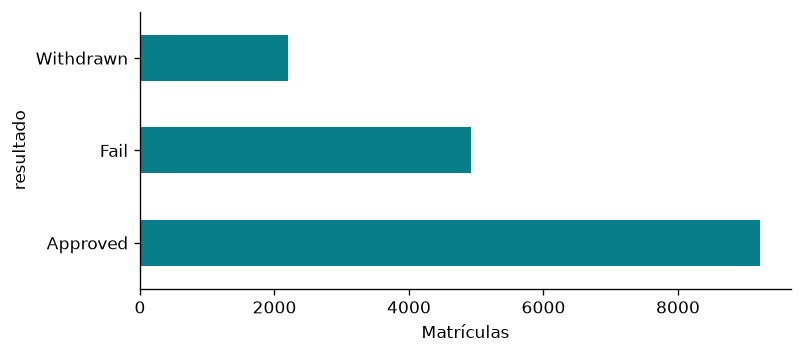

Matrículas: 16331 | personas distintas: 15482


In [3]:
from src.notebooks import desarrollo
train, snapshot, split = desarrollo()
assert len(train) == E['eda']['rows'] and train.id_student.nunique() == E['eda']['unique_students']
assert snapshot['id'] == E['eda']['snapshot_id'] and split['id'] == E['eda']['split_id']
counts = train.target_class.value_counts().rename_axis('resultado').to_frame('matriculas')
display(counts)
counts.plot.barh(legend=False, figsize=(7,3), color='#087e8b'); plt.xlabel('Matrículas'); plt.show()
print('Matrículas:', len(train), '| personas distintas:', train.id_student.nunique())


## Actividad y resultado

Una asociación entre ausencia de registros y Fail puede orientar el contacto. No demuestra que la inactividad cause reprobación ni que una tutoría la evite.

,matriculas,fail,tasa_fail
sin_registros,,,
False,15899,4591,0.28876
True,432,327,0.756944


,proporcion_faltante
click_ratio_14d,0.154063
imd_band,0.035332
recency_days,0.026453
last_activity_day,0.026453
enrollment_key,0.000000
cutoff_day,0.000000
code_presentation,0.000000
code_module,0.000000
edition_key,0.000000
id_student,0.000000


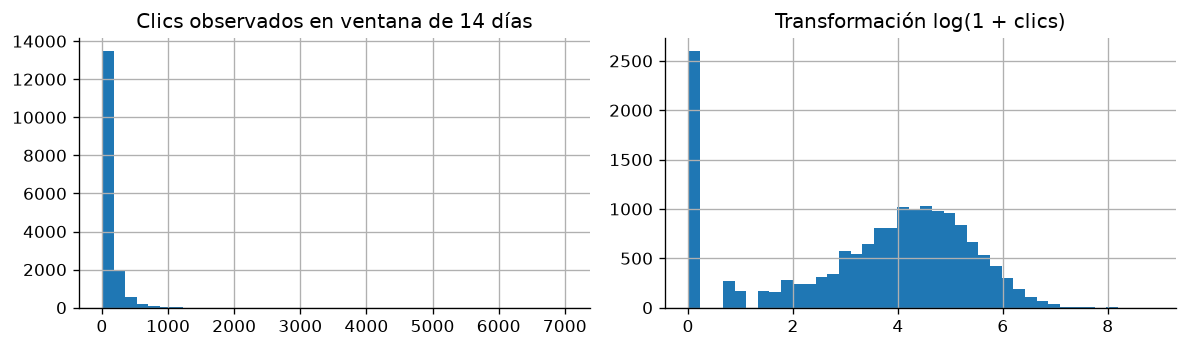

,matriculas,fail
code_module,,
AAA,335,0.125373
BBB,4411,0.304693
CCC,1240,0.300000
DDD,3192,0.312030
EEE,1240,0.275806
FFF,4255,0.299882
GGG,1658,0.329312


In [4]:
activity = train.assign(sin_registros=train.has_recorded_activity.eq(0), fail=train.target_class.eq('Fail'))
summary = activity.groupby('sin_registros').agg(matriculas=('fail','size'), fail=('fail','sum'), tasa_fail=('fail','mean'))
display(summary)
missing = train.isna().mean().sort_values(ascending=False).head(10)
display(missing.rename('proporcion_faltante').to_frame())
fig, axes = plt.subplots(1,2, figsize=(10,3))
train.clicks_current_14d.hist(bins=40, ax=axes[0]); axes[0].set_title('Clics observados en ventana de 14 días')
np.log1p(train.clicks_current_14d).hist(bins=40, ax=axes[1]); axes[1].set_title('Transformación log(1 + clics)')
plt.tight_layout(); plt.show()
display(train.groupby('code_module').agg(matriculas=('target_class','size'), fail=('target_class',lambda x: x.eq('Fail').mean())))


## Lectura final

Los resultados reproducidos pertenecen a los experimentos registrados. La fecha de ejecución de este notebook no los convierte en evidencia nueva de generalización. Consulte `README.md` para insumos, dependencias y comandos del pipeline completo.